In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# La industria manufacturera, 2012–2024

Los grandes agregados de la industria con la EAM, desde 2012 (CIIU Rev. 4). Los montos están en pesos
corrientes: el crecimiento incluye la inflación.

In [2]:
import dane_data as dd

eam = dd.eam.load(range(2012, 2025))
res = dd.eam.resumen(eam, por="anio")
res["valor_agregado_billones"] = res["valor_agregado"] / 1e9     # miles de pesos → billones de pesos
res[["anio", "establecimientos", "personal_total", "valor_agregado_billones", "productividad_laboral",
     "participacion_laboral"]].round(1)

,anio,establecimientos,personal_total,valor_agregado_billones,productividad_laboral,participacion_laboral
0,2012,9489,693303.0,75.3,108599.7,20.3
1,2013,9471,695962.0,78.5,112748.2,20.0
2,2014,9260,704410.0,78.2,111033.8,20.5
3,2015,9015,711444.0,85.7,120522.3,19.7
4,2016,8466,725763.0,88.4,121741.5,20.7
5,2017,8214,717035.0,87.6,122214.1,22.2
6,2018,7911,709021.0,94.4,133118.9,21.7
7,2019,7631,705346.0,96.4,136603.3,22.6
8,2020,7343,660404.0,92.3,139808.9,22.7
9,2021,7138,681246.0,117.0,171697.9,19.6


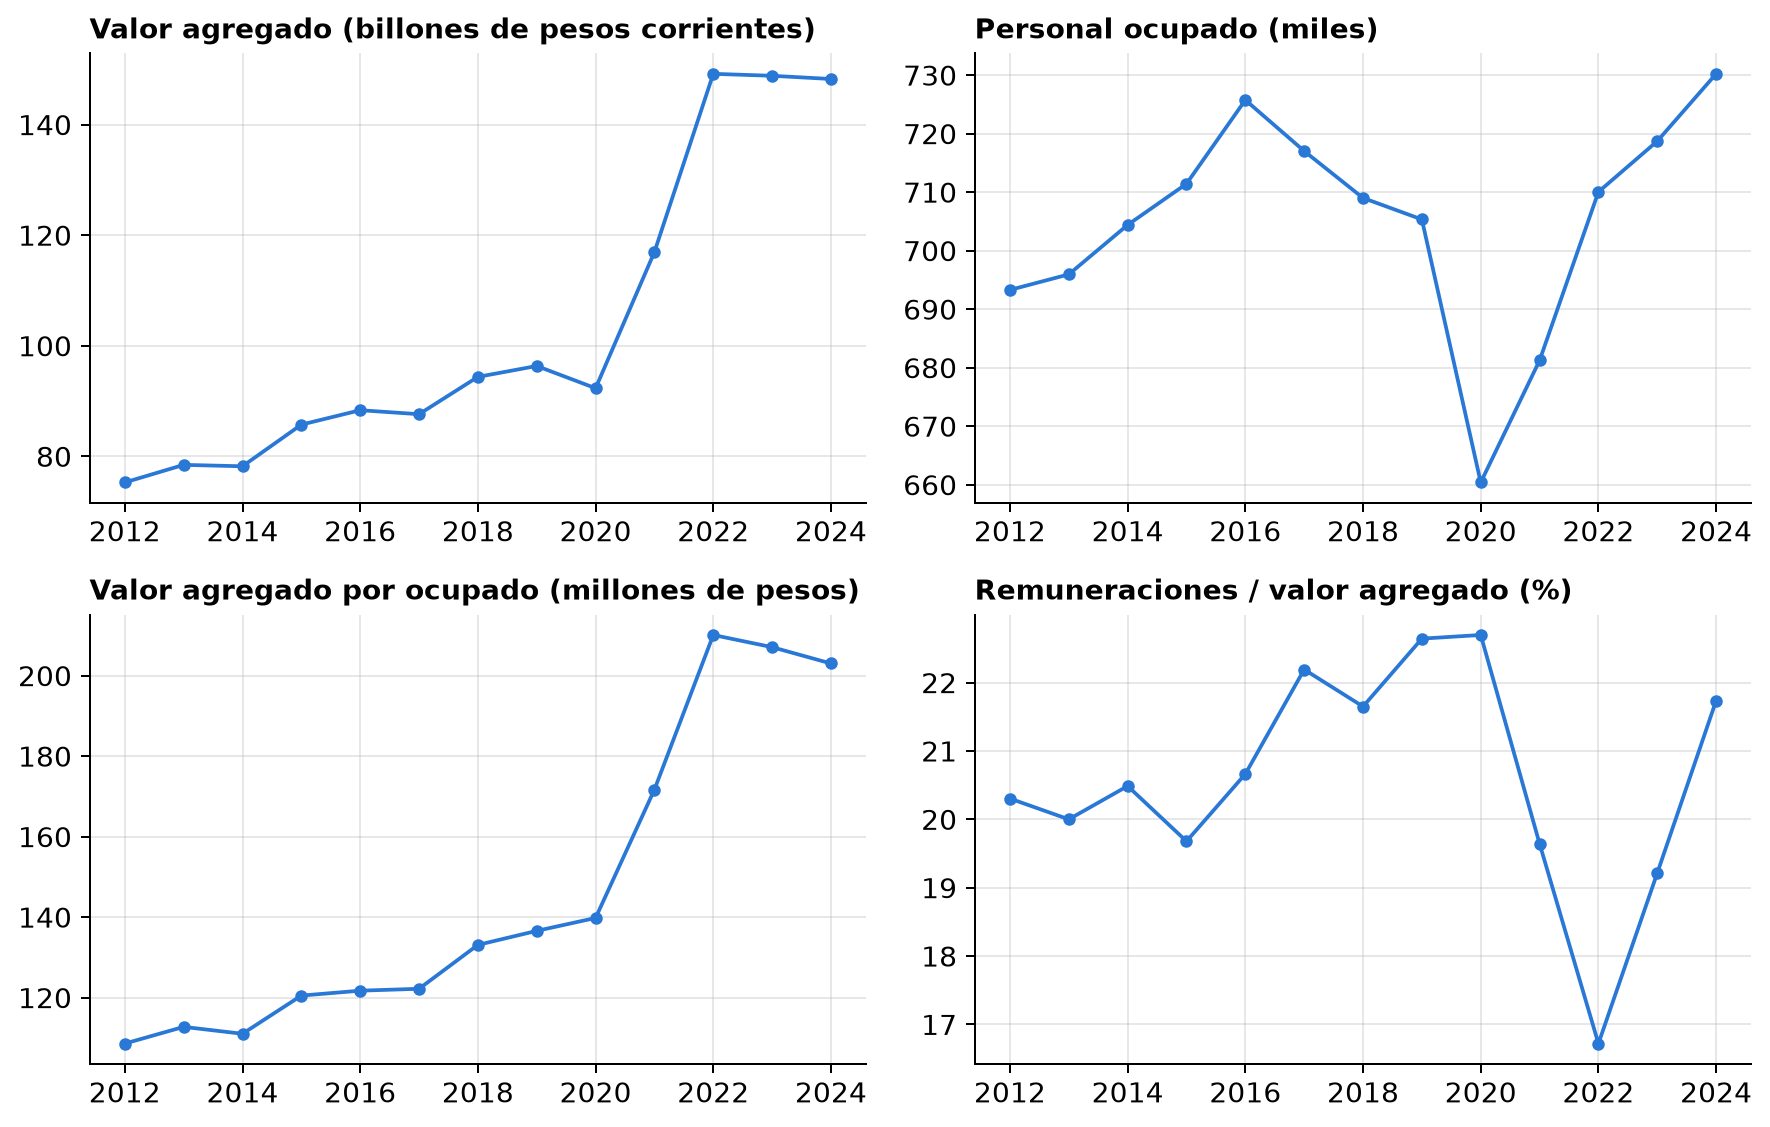

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4))
graficas = [
    ("valor_agregado_billones", "Valor agregado (billones de pesos corrientes)", None),
    ("personal_total", "Personal ocupado (miles)", 1e3),
    ("productividad_laboral", "Valor agregado por ocupado (millones de pesos)", 1e3),
    ("participacion_laboral", "Remuneraciones / valor agregado (%)", None),
]
for ax, (col, titulo, escala) in zip(axes.flat, graficas):
    y = res[col] / escala if escala else res[col]
    ax.plot(res["anio"], y, marker="o", ms=4)
    ax.set_title(titulo, fontsize=11)
fig.tight_layout();

## Por departamento

¿Dónde se genera el valor agregado industrial?

In [4]:
dpto = dd.eam.participacion(eam[eam.anio == 2024], variable="valagri", por="departamento")
dpto.sort_values("participacion", ascending=False).head(8)[["departamento", "participacion"]].round(1)

,departamento,participacion
0,Antioquia,19.2
21,Valle del Cauca,17.3
9,Cundinamarca,15.6
2,Bogotá D.C.,15.3
1,Atlántico,7.6
3,Bolívar,4.7
18,Santander,3.7
7,Cauca,2.8


## Crecimiento del empleo

In [5]:
dd.eam.crecimiento(res, "personal_total")[["anio", "personal_total", "crec_personal_total"]].round(1)

,anio,personal_total,crec_personal_total
0,2012,693303.0,NaN
1,2013,695962.0,0.4
2,2014,704410.0,1.2
3,2015,711444.0,1.0
4,2016,725763.0,2.0
5,2017,717035.0,-1.2
6,2018,709021.0,-1.1
7,2019,705346.0,-0.5
8,2020,660404.0,-6.4
9,2021,681246.0,3.2


```{note}
Para comparar valores entre años, deflacte con {dd}`eam.deflactar()` y un índice de precios (por ejemplo, el
IPP del DANE). Para comparar sectores con los años anteriores a 2012 hace falta una correlativa entre
revisiones de la CIIU (vea {doc}`../guia/eam`).
```